# Charts From Sales Performance Report

Dataset loaded and saved as "df"

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

## Sales Revenue (2021-2023)

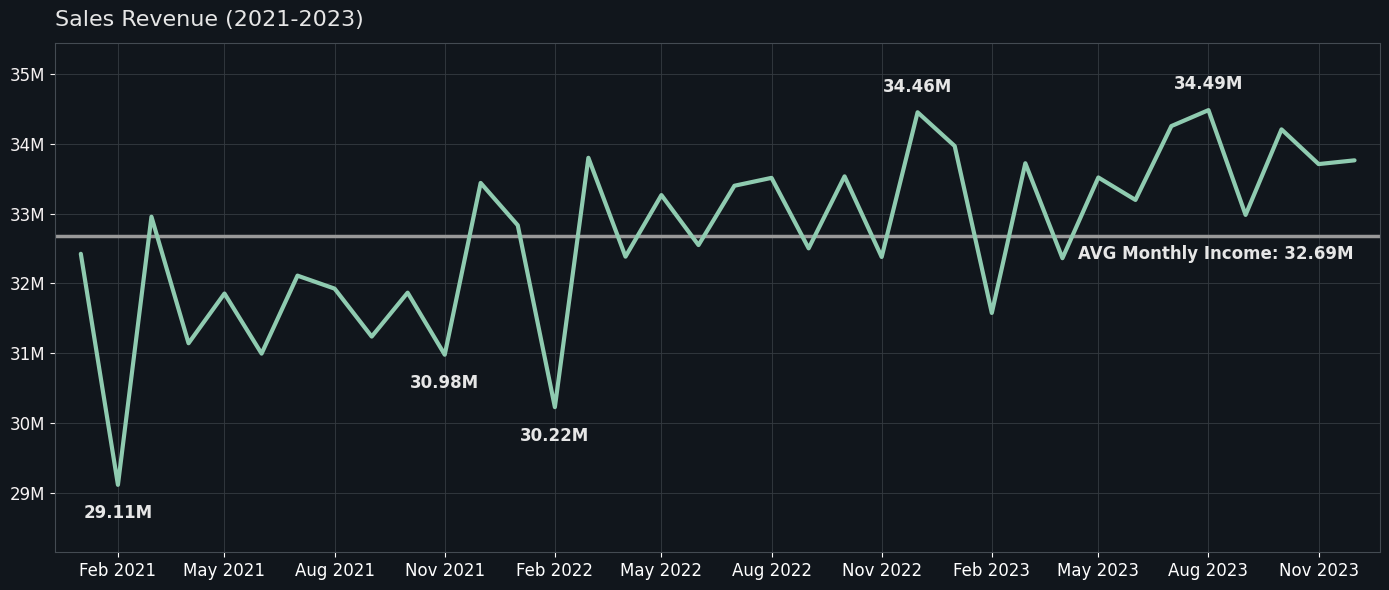

In [10]:
# Clean data
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Total_Price"] = pd.to_numeric(df["Total_Price"], errors="coerce")
df = df.dropna(subset=["Order_Date", "Total_Price"])

# Aggregate revenue by month
monthly_sales = (
    df.set_index("Order_Date")["Total_Price"]
    .resample("MS")
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "Monthly_Revenue"]

# Calculate average revenue
avg_revenue = monthly_sales["Monthly_Revenue"].mean()

# Identify the 2 highest and 3 lowest monthly earnings
top_2 = monthly_sales.nlargest(2, "Monthly_Revenue")
bottom_3 = monthly_sales.nsmallest(3, "Monthly_Revenue")

# Format values as millions
def format_millions(value):
    return f"{value / 1_000_000:.2f}M"

# Create chart
fig, ax = plt.subplots(figsize=(14, 6))

fig.patch.set_facecolor("#11161C")
ax.set_facecolor("#11161C")

# Monthly revenue line - thicker
ax.plot(
    monthly_sales["Month"],
    monthly_sales["Monthly_Revenue"],
    color="#8FCBB0",
    linewidth=3.0,
    solid_capstyle="round",
    zorder=3
)

# Average revenue reference line - thicker
ax.axhline(
    avg_revenue,
    color="#999999",
    linewidth=2.5,
    linestyle="-",
    zorder=2
)

# Average label directly below the average line
ax.annotate(
    f"AVG Monthly Income: {format_millions(avg_revenue)}",
    xy=(0.98, avg_revenue),
    xycoords=("axes fraction", "data"),
    xytext=(0, -7),
    textcoords="offset points",
    ha="right",
    va="top",
    color="#E6E6E6",
    fontsize=12,
    fontweight="bold",
    annotation_clip=False
)

# Highlight the 2 highest monthly earnings
for _, row in top_2.iterrows():
    ax.annotate(
        format_millions(row["Monthly_Revenue"]),
        xy=(row["Month"], row["Monthly_Revenue"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        color="#E6E6E6",
        fontsize=12,
        fontweight="bold",
        annotation_clip=False
    )

# Highlight the 3 lowest monthly earnings
for _, row in bottom_3.iterrows():
    ax.annotate(
        format_millions(row["Monthly_Revenue"]),
        xy=(row["Month"], row["Monthly_Revenue"]),
        xytext=(0, -14),
        textcoords="offset points",
        ha="center",
        va="top",
        color="#E6E6E6",
        fontsize=12,
        fontweight="bold",
        annotation_clip=False
    )

# X-axis: dates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Y-axis: values formatted as XXM
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x / 1_000_000:.0f}M")
)

# Title and styling
ax.set_title(
    "Sales Revenue (2021-2023)",
    loc="left",
    color="#E6E6E6",
    fontsize=16,
    pad=12
)

ax.tick_params(axis="x", colors="#FFFFFF", labelsize=12)
ax.tick_params(axis="y", colors="#F7F3F3", labelsize=12)

# Grid
ax.grid(True, color="#343A40", linewidth=0.7, alpha=0.9)
ax.set_axisbelow(True)

# Border styling
for spine in ax.spines.values():
    spine.set_color("#444B52")

# Add padding so labels are not clipped
ax.margins(x=0.02, y=0.18)

# Final layout
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "Sales Revenue (2021-2023).png",
    dpi=100,
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)
plt.show()

## Sales Trend - Sales Revenue

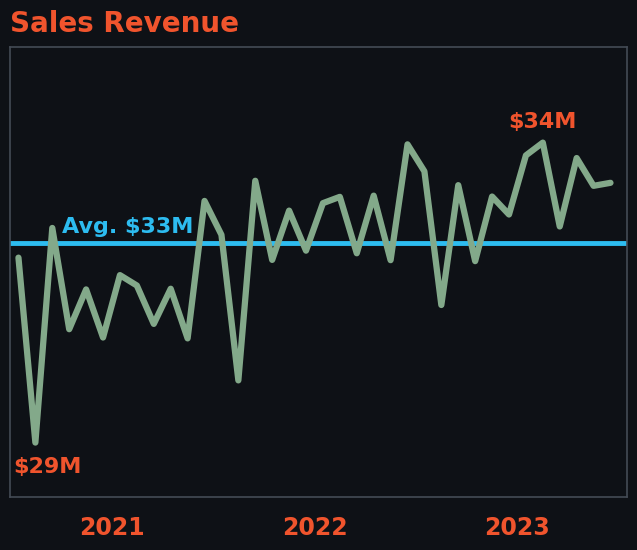

In [ ]:
# CALCULATE MONTHLY SALES REVENUE
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

monthly_sales = (
    df.groupby(df["Order_Date"].dt.to_period("M"))["Total_Price"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "Sales"]
monthly_sales["Month"] = monthly_sales["Month"].dt.to_timestamp()
monthly_sales = monthly_sales.sort_values("Month").reset_index(drop=True)

avg_sales = monthly_sales["Sales"].mean()
max_idx = monthly_sales["Sales"].idxmax()
min_idx = monthly_sales["Sales"].idxmin()

max_month = monthly_sales.loc[max_idx]
min_month = monthly_sales.loc[min_idx]

x = range(len(monthly_sales))

# Format values in millions
def format_millions(value):
    return f"${value / 1_000_000:.0f}M"

# COLORS
bg_color = "#0E1116"
gold = "#F0542D"
green = "#83A98A"
border_color = "#444B55"
yellow = "#F4C542"

# FIGURE SIZE
fig, ax = plt.subplots(figsize=(6.86, 6.08), dpi=100)

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

fig.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.91,
    bottom=0.17
)

# SALES REVENUE LINE
ax.plot(
    x,
    monthly_sales["Sales"],
    color=green,
    linewidth=4.5,
    solid_capstyle="round",
    solid_joinstyle="round",
    antialiased=True,
    zorder=3
)

# AXIS LIMITS
y_min = min(monthly_sales["Sales"].min(), avg_sales)
y_max = max(monthly_sales["Sales"].max(), avg_sales)

y_range = y_max - y_min
if y_range == 0:
    y_range = max(abs(y_max) * 0.1, 1)

ax.set_xlim(-0.5, len(monthly_sales) - 0.5 + 0.5)
ax.set_ylim(
    y_min - y_range * 0.18,
    y_max + y_range * 0.32
)


# AVERAGE LINE
ax.axhline(
    avg_sales,
    color="#2DBCF0",
    linewidth=3.5,
    zorder=2
)

ax.annotate(
    f"Avg. {format_millions(avg_sales)}",
    xy=(0.055, avg_sales),
    xycoords=("axes fraction", "data"),
    xytext=(13, 5),
    textcoords="offset points",
    color="#2DBCF0",
    fontsize=16,
    fontweight="bold",
    ha="left",
    va="bottom",
    zorder=4
)


# HIGHEST VALUE
ax.annotate(
    format_millions(max_month["Sales"]),
    xy=(max_idx, max_month["Sales"]),
    xytext=(0, 8),
    textcoords="offset points",
    color=gold,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="bottom",
    annotation_clip=True,
    zorder=4
)


# LOWEST VALUE
ax.annotate(
    format_millions(min_month["Sales"]),
    xy=(min_idx, min_month["Sales"]),
    xytext=(9, -10),
    textcoords="offset points",
    color=gold,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="top",
    annotation_clip=True,
    zorder=4
)

# ==========================================
# TITLE
# ==========================================

ax.text(
    0.0, 1.02, "Sales Revenue",
    transform=ax.transAxes,
    color=gold,
    fontsize=20,
    fontweight="bold",
    ha="left",
    va="bottom"
)

# ==========================================
# X-AXIS: YEAR LABELS ONLY
# ==========================================

years = monthly_sales["Month"].dt.year
year_positions = []

for year in years.unique():
    indices = [
        i for i, value in enumerate(years)
        if value == year
    ]
    year_positions.append((year, sum(indices) / len(indices)))

ax.set_xticks([pos for _, pos in year_positions])
ax.set_xticklabels([str(year) for year, _ in year_positions])

ax.tick_params(
    axis="x",
    colors=gold,
    labelsize=17,
    length=0,
    pad=14
)

for label in ax.get_xticklabels():
    label.set_fontweight("bold")

# ==========================================
# HIDE Y-AXIS AND GRIDLINES
# ==========================================
ax.set_yticks([])
ax.grid(False)

# BORDER
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(border_color)
    spine.set_linewidth(1.2)

# SAVE
plt.savefig(
    "monthly_sales_revenue.png",
    dpi=100,
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)

plt.show()

## Sales Trend - AOV

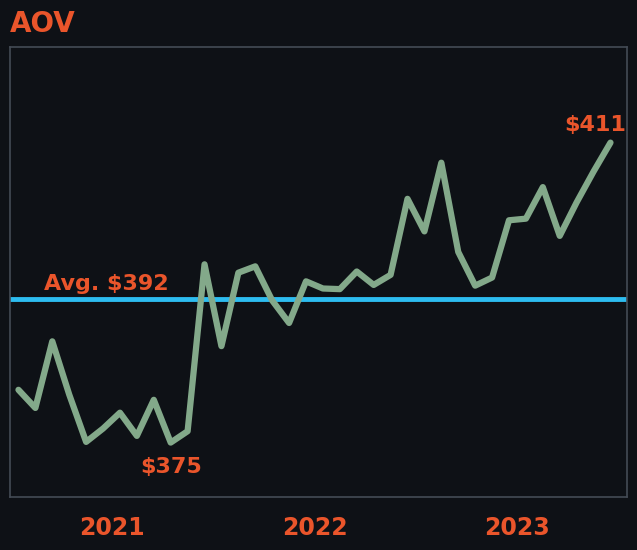

In [ ]:
# CALCULATE MONTHLY AOV

# Ensure Order_Date is a datetime column
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# Calculate the total value of each order
order_totals = (
    df.groupby(["Order_ID", "Order_Date"], as_index=False)
      ["Total_Price"]
      .sum()
)

# Calculate average order value for each month
order_totals["Month"] = (
    order_totals["Order_Date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_aov = (
    order_totals.groupby("Month", as_index=False)
    ["Total_Price"]
    .mean()
    .rename(columns={"Total_Price": "AOV"})
)

# CALCULATE SUMMARY VALUES
monthly_aov = monthly_aov.sort_values("Month").reset_index(drop=True)

avg_aov = monthly_aov["AOV"].mean()

max_month = monthly_aov.loc[monthly_aov["AOV"].idxmax()]
min_month = monthly_aov.loc[monthly_aov["AOV"].idxmin()]

# Use equally spaced positions for every month
x = range(len(monthly_aov))

max_idx = monthly_aov["AOV"].idxmax()
min_idx = monthly_aov["AOV"].idxmin()

# COLORS
bg_color = "#0E1116"
gold = "#EA552B"
green = "#83A98A"
border_color = "#444B55"
avg_line_color = "#2DBCF0"

# Average line
ax.axhline(
    avg_aov,
    color=avg_line_color,
    linewidth=3.5,
    zorder=2
)

# FIGURE SIZE
fig, ax = plt.subplots(figsize=(6.86, 6.08), dpi=100)

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

fig.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.91,
    bottom=0.17
)

# AOV LINE
ax.plot(
    x,
    monthly_aov["AOV"],
    color=green,
    linewidth=4.5,
    solid_capstyle="round",
    solid_joinstyle="round",
    antialiased=True,
    zorder=3
)

# AXIS LIMITS
y_min = min(monthly_aov["AOV"].min(), avg_aov)
y_max = max(monthly_aov["AOV"].max(), avg_aov)

y_range = y_max - y_min
if y_range == 0:
    y_range = max(abs(y_max) * 0.1, 1)

ax.set_xlim(-0.5, len(monthly_aov) - 0.5 + 0.5)

# Extra headroom above the maximum for the $411 label
ax.set_ylim(
    y_min - y_range * 0.18,
    y_max + y_range * 0.32
)

# AVERAGE LINE
ax.axhline(
    avg_aov,
    color=avg_line_color,
    linewidth=3.5,
    zorder=2
)

# Average label: offset above the line in screen points
ax.annotate(
    f"Avg. ${avg_aov:.0f}",
    xy=(0.055, avg_aov),
    xycoords=("axes fraction", "data"),
    xytext=(0, 4),
    textcoords="offset points",
    color=gold,
    fontsize=16,
    fontweight="bold",
    ha="left",
    va="bottom",
    zorder=4
)

# HIGHEST VALUE
ax.annotate(
    f"${max_month['AOV']:.0f}",
    xy=(max_idx, max_month["AOV"]),
    xytext=(-11, 6),
    textcoords="offset points",
    color=gold,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="bottom",
    annotation_clip=True,
    zorder=4
)

# LOWEST VALUE
ax.annotate(
    f"${min_month['AOV']:.0f}",
    xy=(min_idx, min_month["AOV"]),
    xytext=(0, -10),
    textcoords="offset points",
    color=gold,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="top",
    annotation_clip=False,
    zorder=4
)

# TITLE
ax.text(
    0.0,
    1.02,
    "AOV",
    transform=ax.transAxes,
    color=gold,
    fontsize=20,
    fontweight="bold",
    ha="left",
    va="bottom"
)

# X-AXIS
year_labels = monthly_aov["Month"].dt.year
year_positions = []

for year in year_labels.unique():
    indices = [
        i for i, value in enumerate(year_labels)
        if value == year
    ]
    year_positions.append((year, sum(indices) / len(indices)))

# Place each year label at the center of its months
ax.set_xticks([pos for _, pos in year_positions])
ax.set_xticklabels([str(year) for year, _ in year_positions])

ax.tick_params(
    axis="x",
    colors=gold,
    labelsize=17,
    length=0,
    pad=14
)

for label in ax.get_xticklabels():
    label.set_fontweight("bold")

# ==========================================
# HIDE Y-AXIS AND GRIDLINES
# ======================
ax.set_yticks([])
ax.grid(False)

# BORDER
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(border_color)
    spine.set_linewidth(1.2)

# SAVE
plt.savefig(
    "aov_sales_chart.png",
    dpi=100,
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)

plt.show()


## Sales Trend - Total Orders

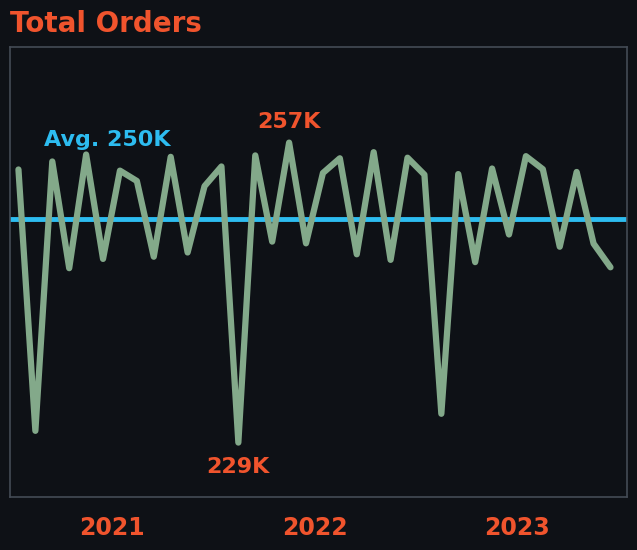

In [ ]:
# CALCULATE MONTHLY TOTAL ORDERS
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

monthly_orders = (
    df.groupby(df["Order_Date"].dt.to_period("M"))["Order_ID"]
    .count()
    .reset_index()
)

monthly_orders.columns = ["Month", "Orders"]
monthly_orders["Month"] = monthly_orders["Month"].dt.to_timestamp()
monthly_orders = monthly_orders.sort_values("Month").reset_index(drop=True)

avg_orders = monthly_orders["Orders"].mean()
max_idx = monthly_orders["Orders"].idxmax()
min_idx = monthly_orders["Orders"].idxmin()

max_month = monthly_orders.loc[max_idx]
min_month = monthly_orders.loc[min_idx]

x = range(len(monthly_orders))

# Format values in thousands
def format_thousands(value):
    return f"{value / 1_000:.0f}K"

# COLORS
bg_color = "#0E1116"
gold = "#F0542D"
green = "#83A98A"
border_color = "#444B55"

# FIGURE SIZE
fig, ax = plt.subplots(figsize=(6.86, 6.08), dpi=100)

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

fig.subplots_adjust(
    left=0.05,
    right=0.95,
    top=0.91,
    bottom=0.17
)

# ORDERS LINE
ax.plot(
    x,
    monthly_orders["Orders"],
    color=green,
    linewidth=4.5,
    solid_capstyle="round",
    solid_joinstyle="round",
    antialiased=True,
    zorder=3
)

# AXIS LIMITS
y_min = min(monthly_orders["Orders"].min(), avg_orders)
y_max = max(monthly_orders["Orders"].max(), avg_orders)

y_range = y_max - y_min
if y_range == 0:
    y_range = max(abs(y_max) * 0.1, 1)

ax.set_xlim(-0.5, len(monthly_orders) - 0.5 + 0.5)
ax.set_ylim(
    y_min - y_range * 0.18,
    y_max + y_range * 0.32
)

# AVERAGE LINE
ax.axhline(
    avg_orders,
    color="#2DBCF0",
    linewidth=3.5,
    zorder=2
)

ax.annotate(
    f"Avg. {format_thousands(avg_orders)}",
    xy=(0.055, avg_orders),
    xycoords=("axes fraction", "data"),
    xytext=(0, 50),
    textcoords="offset points",
    color="#2DBCF0",
    fontsize=16,
    fontweight="bold",
    ha="left",
    va="bottom",
    zorder=4
)

# HIGHEST VALUE
ax.annotate(
    format_thousands(max_month["Orders"]),
    xy=(max_idx, max_month["Orders"]),
    xytext=(0, 8),
    textcoords="offset points",
    color=gold,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="bottom",
    annotation_clip=True,
    zorder=4
)

# LOWEST VALUE
ax.annotate(
    format_thousands(min_month["Orders"]),
    xy=(min_idx, min_month["Orders"]),
    xytext=(0, -10),
    textcoords="offset points",
    color=gold,
    fontsize=16,
    fontweight="bold",
    ha="center",
    va="top",
    annotation_clip=True,
    zorder=4
)

# TITLE
ax.text(
    0.0, 1.02, "Total Orders",
    transform=ax.transAxes,
    color=gold,
    fontsize=20,
    fontweight="bold",
    ha="left",
    va="bottom"
)

# X-AXIS: YEAR LABELS ONLY
years = monthly_orders["Month"].dt.year
year_positions = []

for year in years.unique():
    indices = [
        i for i, value in enumerate(years)
        if value == year
    ]
    year_positions.append((year, sum(indices) / len(indices)))

ax.set_xticks([pos for _, pos in year_positions])
ax.set_xticklabels([str(year) for year, _ in year_positions])

ax.tick_params(
    axis="x",
    colors=gold,
    labelsize=17,
    length=0,
    pad=14
)

for label in ax.get_xticklabels():
    label.set_fontweight("bold")

# HIDE Y-AXIS AND GRIDLINES
ax.set_yticks([])
ax.grid(False)

# BORDER
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(border_color)
    spine.set_linewidth(1.2)

# SAVE AND DISPLAY
plt.savefig(
    "monthly_total_orders.png",
    dpi=100,
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)

plt.show()


## Regional Sales - Sales

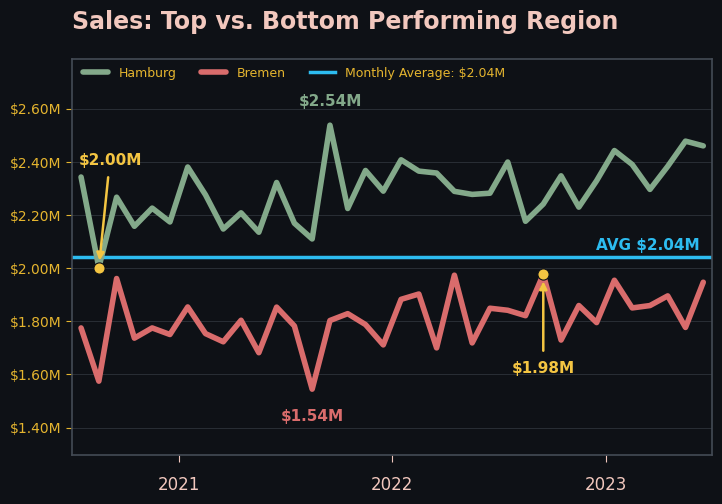

In [ ]:
# CALCULATE MONTHLY SALES BY REGION
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

monthly_sales = (
    df.groupby([
        df["Order_Date"].dt.to_period("M"),
        "Region"
    ])["Total_Price"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "Region", "Sales"]
monthly_sales["Month"] = monthly_sales["Month"].dt.to_timestamp()
monthly_sales = monthly_sales.sort_values("Month").reset_index(drop=True)

months = sorted(monthly_sales["Month"].unique())
month_positions = {
    pd.Timestamp(month): i
    for i, month in enumerate(months)
}

monthly_sales["X"] = monthly_sales["Month"].map(month_positions)


# IDENTIFY TOP AND BOTTOM REGIONS
region_totals = (
    monthly_sales.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

top_region = region_totals.index[0]
bottom_region = region_totals.index[-1]

top_data = monthly_sales[
    monthly_sales["Region"] == top_region
].copy()

bottom_data = monthly_sales[
    monthly_sales["Region"] == bottom_region
].copy()

# MONTHLY AVERAGE
avg_sales = monthly_sales.groupby("Month")["Sales"].mean().mean()

# FORMAT VALUES
def format_millions(value):
    return f"${value / 1_000_000:.2f}M"

# FIND EXTREME VALUES
top_max = top_data.loc[top_data["Sales"].idxmax()]
top_min = top_data.loc[top_data["Sales"].idxmin()]

bottom_max = bottom_data.loc[bottom_data["Sales"].idxmax()]
bottom_min = bottom_data.loc[bottom_data["Sales"].idxmin()]

# Bremen maximum and Hamburg minimum are special annotations
bremen_data = monthly_sales[
    monthly_sales["Region"] == "Bremen"
]

hamburg_data = monthly_sales[
    monthly_sales["Region"] == "Hamburg"
]

bremen_max = bremen_data.loc[bremen_data["Sales"].idxmax()]
hamburg_min = hamburg_data.loc[hamburg_data["Sales"].idxmin()]

# COLORS
bg_color = "#0E1116"
gold = "#F2C8BE"
green = "#83A98A"
red = "#D96C6C"
blue = "#2DBCF0"
border_color = "#444B55"
text_color = "#E5B52F"


# FIGURE
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

fig.subplots_adjust(
    left=0.15,
    right=0.95,
    top=0.84,
    bottom=0.18
)

# TOP-PERFORMING REGION
ax.plot(
    top_data["X"],
    top_data["Sales"],
    color=green,
    linewidth=4,
    solid_capstyle="round",
    solid_joinstyle="round",
    label=f"{top_region}",
    zorder=3
)

# BOTTOM-PERFORMING REGION
ax.plot(
    bottom_data["X"],
    bottom_data["Sales"],
    color=red,
    linewidth=4,
    solid_capstyle="round",
    solid_joinstyle="round",
    label=f"{bottom_region}",
    zorder=3
)

# MONTHLY AVERAGE LINE
ax.axhline(
    avg_sales,
    color=blue,
    linewidth=2.5,
    label=f"Monthly Average: {format_millions(avg_sales)}",
    zorder=2
)

ax.annotate(
    f"AVG {format_millions(avg_sales)}",
    xy=(0.98, avg_sales),
    xycoords=("axes fraction", "data"),
    xytext=(0, 3),
    textcoords="offset points",
    color=blue,
    fontsize=11,
    fontweight="bold",
    ha="right",
    va="bottom",
    zorder=6
)


# REGULAR MAXIMUM/MINIMUM LABELS
def same_point(point_a, point_b):
    return (
        point_a["Month"] == point_b["Month"]
        and point_a["Region"] == point_b["Region"]
    )

def annotate_extremes(data, color):
    max_point = data.loc[data["Sales"].idxmax()]
    min_point = data.loc[data["Sales"].idxmin()]

    # Label maximum unless it is Bremen's special maximum
    if not same_point(max_point, bremen_max):
        ax.annotate(
            format_millions(max_point["Sales"]),
            xy=(max_point["X"], max_point["Sales"]),
            xytext=(0, 12),
            textcoords="offset points",
            color=color,
            fontsize=11,
            fontweight="bold",
            ha="center",
            va="bottom",
            annotation_clip=False,
            zorder=5
        )

    # Label minimum unless it is Hamburg's special minimum
    if not same_point(min_point, hamburg_min):
        ax.annotate(
            format_millions(min_point["Sales"]),
            xy=(min_point["X"], min_point["Sales"]),
            xytext=(0, -14),
            textcoords="offset points",
            color=color,
            fontsize=11,
            fontweight="bold",
            ha="center",
            va="top",
            annotation_clip=False,
            zorder=5
        )

annotate_extremes(top_data, green)
annotate_extremes(bottom_data, red)

# BREMEN MAXIMUM
ax.scatter(
    bremen_max["X"],
    bremen_max["Sales"],
    color=yellow,
    edgecolors=bg_color,
    linewidths=0.8,
    s=65,
    zorder=8
)

ax.annotate(
    format_millions(bremen_max["Sales"]),
    xy=(bremen_max["X"], bremen_max["Sales"]),
    xytext=(0, -62),
    textcoords="offset points",
    color=yellow,
    fontsize=11,
    fontweight="bold",
    ha="center",
    va="top",
    arrowprops=dict(
        arrowstyle="-|>",
        color=yellow,
        linewidth=1.8,
        shrinkA=5,
        shrinkB=5
    ),
    annotation_clip=False,
    zorder=7
)

# HAMBURG MINIMUM
ax.scatter(
    hamburg_min["X"],
    hamburg_min["Sales"],
    color=yellow,
    edgecolors=bg_color,
    linewidths=0.8,
    s=65,
    zorder=8
)

ax.annotate(
    format_millions(hamburg_min["Sales"]),
    xy=(hamburg_min["X"], hamburg_min["Sales"]),
    xytext=(8, 72),
    textcoords="offset points",
    color=yellow,
    fontsize=11,
    fontweight="bold",
    ha="center",
    va="bottom",
    arrowprops=dict(
        arrowstyle="-|>",
        color=yellow,
        linewidth=1.8,
        shrinkA=5,
        shrinkB=5
    ),
    annotation_clip=False,
    zorder=7
)

# TITLE
ax.set_title(
    "Sales: Top vs. Bottom Performing Region",
    color=gold,
    fontsize=17,
    fontweight="bold",
    loc="left",
    pad=22
)

# X-AXIS: YEAR LABELS
years = pd.Series(months).dt.year
year_positions = []

for year in years.unique():
    indices = [
        i for i, value in enumerate(years)
        if value == year
    ]
    year_positions.append((year, sum(indices) / len(indices)))

ax.set_xticks([position for _, position in year_positions])
ax.set_xticklabels([str(year) for year, _ in year_positions])

ax.tick_params(
    axis="x",
    colors=gold,
    labelsize=12,
    length=5,
    pad=10
)

# VISIBLE Y-AXIS
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda value, _: format_millions(value)
    )
)

ax.tick_params(
    axis="y",
    colors=text_color,
    labelsize=10,
    length=4
)

# AXIS LIMITS
all_values = pd.concat([
    top_data["Sales"],
    bottom_data["Sales"],
    pd.Series([avg_sales])
])

y_min = all_values.min()
y_max = all_values.max()
y_range = y_max - y_min

if y_range == 0:
    y_range = max(abs(y_max) * 0.1, 1)

ax.set_xlim(-0.5, len(months) - 0.5)

# Extra space for arrow labels above and below
ax.set_ylim(
    y_min - y_range * 0.25,
    y_max + y_range * 0.25
)

# GRID AND BORDERS
ax.grid(
    axis="y",
    color=border_color,
    linewidth=0.7,
    alpha=0.5
)

ax.grid(axis="x", visible=False)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(border_color)
    spine.set_linewidth(1.2)

# LEGEND
legend = ax.legend(
    loc="upper left",
    bbox_to_anchor=(0, 1.01),
    ncol=3,
    frameon=False,
    fontsize=9
)

for label in legend.get_texts():
    label.set_color(text_color)

# SAVE AND DISPLAY
plt.savefig(
    "monthly_sales_top_bottom_regions.png",
    dpi=100,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()

## Regional Sales - AOV

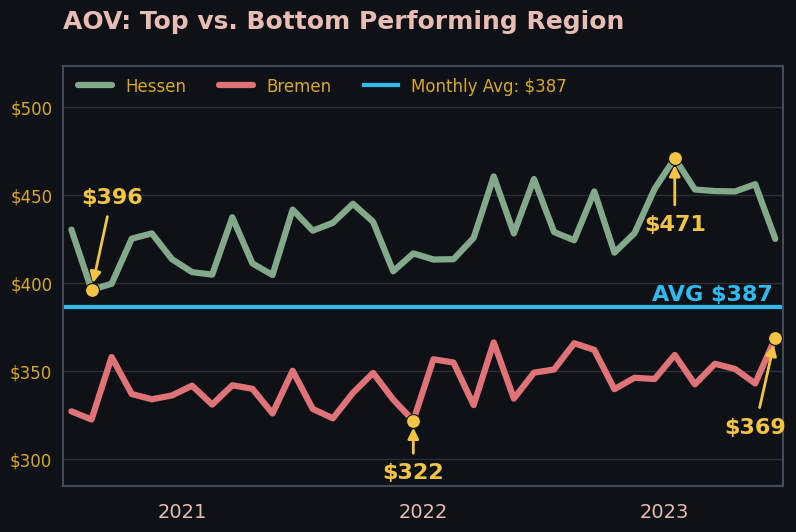

In [ ]:
# Prepare the data
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

# Add up all product prices for each order
order_totals = (
    df.groupby(["Order_ID", "Order_Date", "Region"], as_index=False)
      ["Total_Price"].sum()
)

# Get the average order value for each month and region
order_totals["Month"] = (
    order_totals["Order_Date"].dt.to_period("M").dt.to_timestamp()
)

monthly_region_aov = (
    order_totals.groupby(["Month", "Region"], as_index=False)
    ["Total_Price"].mean()
    .rename(columns={"Total_Price": "AOV"})
)

# Keep only Hessen and Bremen
top_data = (
    monthly_region_aov[monthly_region_aov["Region"] == "Hessen"]
    .sort_values("Month")
    .reset_index(drop=True)
)

bottom_data = (
    monthly_region_aov[monthly_region_aov["Region"] == "Bremen"]
    .sort_values("Month")
    .reset_index(drop=True)
)

# Make sure both regions have data
if top_data.empty or bottom_data.empty:
    raise ValueError("Check that the Region column contains Hessen and Bremen.")

# Use the same x positions for both lines
months = sorted(
    set(top_data["Month"]).intersection(set(bottom_data["Month"]))
)

top_data = (
    top_data[top_data["Month"].isin(months)]
    .sort_values("Month").reset_index(drop=True)
)

bottom_data = (
    bottom_data[bottom_data["Month"].isin(months)]
    .sort_values("Month").reset_index(drop=True)
)

# Calculate the overall average of the two regions' monthly AOVs
avg_aov = pd.concat([top_data["AOV"], bottom_data["AOV"]]).mean()

# Find the highest and lowest points for each region
hessen_max = top_data.loc[top_data["AOV"].idxmax()]
hessen_min = top_data.loc[top_data["AOV"].idxmin()]
bremen_max = bottom_data.loc[bottom_data["AOV"].idxmax()]
bremen_min = bottom_data.loc[bottom_data["AOV"].idxmin()]

# Chart colors
bg_color = "#0E1116"
green = "#83A98A"
red = "#DF7377"
yellow = "#F4C542"
blue = "#2DBCF0"
border_color = "#444B55"

# Create the chart
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.85,
    bottom=0.15
)

# Plot the monthly AOV for both regions
ax.plot(
    range(len(top_data)),
    top_data["AOV"],
    color=green,
    linewidth=4.5,
    solid_capstyle="round",
    label="Hessen",
    zorder=3
)

ax.plot(
    range(len(bottom_data)),
    bottom_data["AOV"],
    color=red,
    linewidth=4.5,
    solid_capstyle="round",
    label="Bremen",
    zorder=3
)

# Add a line for the average AOV
ax.axhline(
    avg_aov,
    color=blue,
    linewidth=3,
    label=f"Monthly Avg: ${avg_aov:.0f}",
    zorder=2
)

# Add a label above the average line
ax.text(
    0.985,
    avg_aov + 1,
    f"AVG ${avg_aov:.0f}",
    transform=ax.get_yaxis_transform(),
    color=blue,
    fontsize=16,
    fontweight="bold",
    ha="right",
    va="bottom"
)

# Mark the highest and lowest points
def add_label(row, index, value, direction, x_offset=0, y_offset=0):
    # Draw a dot on the point we want to highlight
    ax.scatter(
        index,
        value,
        color=yellow,
        edgecolors=bg_color,
        linewidths=0.8,
        s=100,
        zorder=6
    )

    # Add an arrow and the value label
    ax.annotate(
        f"${value:.0f}",
        xy=(index, value),
        xytext=(index + x_offset, value + y_offset),
        textcoords="data",
        color=yellow,
        fontsize=16,
        fontweight="bold",
        ha="center",
        va="bottom" if y_offset > 0 else "top",
        arrowprops=dict(
            arrowstyle="-|>",
            color=yellow,
            linewidth=2,
            shrinkA=5,
            shrinkB=5
        ),
        zorder=7
    )

# Hessen's lowest and highest AOV
add_label(
    hessen_min,
    hessen_min.name,
    hessen_min["AOV"],
    "up",
    x_offset=1,
    y_offset=47
)

add_label(
    hessen_max,
    hessen_max.name,
    hessen_max["AOV"],
    "down",
    x_offset=0,
    y_offset=-32
)

# Bremen's lowest and highest AOV
add_label(
    bremen_min,
    bremen_min.name,
    bremen_min["AOV"],
    "down",
    x_offset=0,
    y_offset=-24
)

add_label(
    bremen_max,
    bremen_max.name,
    bremen_max["AOV"],
    "up",
    x_offset=-1,
    y_offset=-45
)

# Title and legend
ax.text(
    0,
    1.09,
    "AOV: Top vs. Bottom Performing Region",
    transform=ax.transAxes,
    color="#E9BDB4",
    fontsize=18,
    fontweight="bold",
    ha="left"
)

legend = ax.legend(
    loc="upper left",
    bbox_to_anchor=(0, 1.01),
    ncol=3,
    frameon=False,
    fontsize=12
)

for text_item in legend.get_texts():
    text_item.set_color("#D9A927")

# X-axis labels
year_labels = pd.Series(months).dt.year
year_positions = []

for year in year_labels.unique():
    positions = [
        i for i, current_year in enumerate(year_labels)
        if current_year == year
    ]
    year_positions.append((year, sum(positions) / len(positions)))

ax.set_xticks([pos for year, pos in year_positions])
ax.set_xticklabels([str(year) for year, pos in year_positions])

ax.tick_params(
    axis="x",
    colors="#E9BDB4",
    labelsize=14,
    length=0,
    pad=12
)

# Y-axis and borders
# Keep the dollar values on the y-axis
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, position: f"${value:.0f}")
)

ax.tick_params(
    axis="y",
    colors="#D9A927",
    labelsize=12,
    length=0,
    pad=8
)

# Add horizontal gridlines
ax.grid(
    axis="y",
    color=border_color,
    linewidth=1,
    alpha=0.55
)

ax.grid(axis="x", visible=False)

# Leave space around the highest and lowest points
all_values = pd.concat([top_data["AOV"], bottom_data["AOV"]])
y_min = min(all_values.min(), avg_aov)
y_max = max(all_values.max(), avg_aov)
y_range = max(y_max - y_min, 1)

ax.set_ylim(y_min - y_range * 0.25, y_max + y_range * 0.35)
ax.set_xlim(-0.4, len(months) - 0.6)

for spine in ax.spines.values():
    spine.set_color(border_color)
    spine.set_linewidth(1.5)

# Save chart and display it
plt.savefig(
    "aov_top_bottom_regions.png",
    dpi=100,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()


## Regional Sales - Total Orders

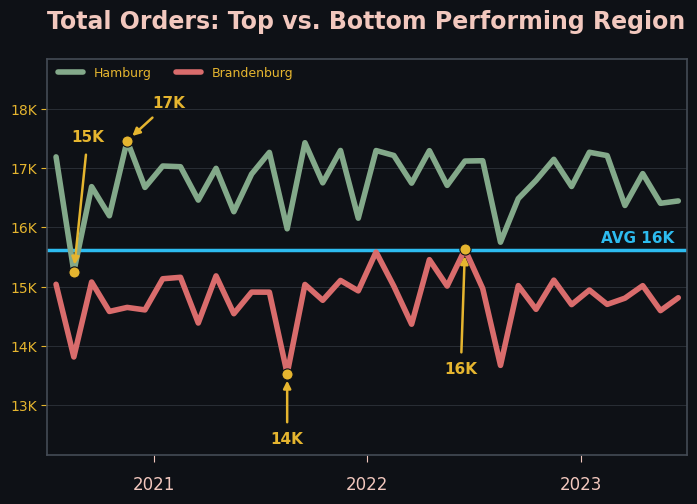

In [ ]:
# CALCULATE MONTHLY ORDER RECORDS BY REGION
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

monthly_orders = (
    df.groupby([
        df["Order_Date"].dt.to_period("M"),
        "Region"
    ])
    .size()
    .reset_index(name="Orders")
)

monthly_orders.columns = ["Month", "Region", "Orders"]
monthly_orders["Month"] = monthly_orders["Month"].dt.to_timestamp()
monthly_orders = monthly_orders.sort_values("Month").reset_index(drop=True)

months = sorted(monthly_orders["Month"].unique())
month_positions = {pd.Timestamp(m): i for i, m in enumerate(months)}

monthly_orders["X"] = monthly_orders["Month"].map(month_positions)

# IDENTIFY TOP AND BOTTOM REGIONS
region_totals = (
    monthly_orders.groupby("Region")["Orders"]
    .sum()
    .sort_values(ascending=False)
)

top_region = region_totals.index[0]
bottom_region = region_totals.index[-1]

top_data = monthly_orders[
    monthly_orders["Region"] == top_region
].copy()

bottom_data = monthly_orders[
    monthly_orders["Region"] == bottom_region
].copy()

# MONTHLY AVERAGE
avg_orders = monthly_orders.groupby("Month")["Orders"].mean().mean()

# FORMAT VALUES
def format_orders(value):
    return f"{value / 1_000:.0f}K"

# FIND EXTREME VALUES
top_max = top_data.loc[top_data["Orders"].idxmax()]
top_min = top_data.loc[top_data["Orders"].idxmin()]

bottom_max = bottom_data.loc[bottom_data["Orders"].idxmax()]
bottom_min = bottom_data.loc[bottom_data["Orders"].idxmin()]

# COLORS
bg_color = "#0E1116"
gold = "#F2C8BE"
green = "#83A98A"
red = "#D96C6C"
blue = "#2DBCF0"
yellow = "#E5B52F"
border_color = "#444B55"
text_color = "#E5B52F"

# CUSTOM ANNOTATION SETTINGS
annotation_settings = {
    "top_max": {
        "xytext": (30, 22),
        "ha": "center",
        "va": "bottom",
        "arrowstyle": "-|>",
        "arrow_color": yellow,
        "arrow_width": 1.8,
        "dot_color": yellow,
    },

    "top_min": {
        "xytext": (10, 102),
        "ha": "center",
        "va": "top",
        "arrowstyle": "-|>",
        "arrow_color": yellow,
        "arrow_width": 1.8,
        "dot_color": yellow,
    },

    "bottom_max": {
        "xytext": (-3, -92),
        "ha": "center",
        "va": "bottom",
        "arrowstyle": "-|>",
        "arrow_color": yellow,
        "arrow_width": 1.8,
        "dot_color": yellow,
    },

    "bottom_min": {
        "xytext": (0, -42),
        "ha": "center",
        "va": "top",
        "arrowstyle": "-|>",
        "arrow_color": yellow,
        "arrow_width": 1.8,
        "dot_color": yellow,
    },
}

# FIGURE
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

fig.subplots_adjust(
    left=0.15,
    right=0.95,
    top=0.84,
    bottom=0.18
)

# TOP-PERFORMING REGION
ax.plot(
    top_data["X"],
    top_data["Orders"],
    color=green,
    linewidth=4,
    solid_capstyle="round",
    solid_joinstyle="round",
    label=f"{top_region}",
    zorder=3
)

# BOTTOM-PERFORMING REGION
ax.plot(
    bottom_data["X"],
    bottom_data["Orders"],
    color=red,
    linewidth=4,
    solid_capstyle="round",
    solid_joinstyle="round",
    label=f"{bottom_region}",
    zorder=3
)

# MONTHLY AVERAGE LINE
ax.axhline(
    avg_orders,
    color=blue,
    linewidth=2.5,
    zorder=2
)

ax.annotate(
    f"AVG {format_orders(avg_orders)}",
    xy=(0.98, avg_orders),
    xycoords=("axes fraction", "data"),
    xytext=(0, 3),
    textcoords="offset points",
    color=blue,
    fontsize=11,
    fontweight="bold",
    ha="right",
    va="bottom",
    zorder=6
)

# ANNOTATE EXTREME VALUES
def annotate_point(point, settings):
    # Draw the highlighted dot
    ax.scatter(
        point["X"],
        point["Orders"],
        color=settings["dot_color"],
        edgecolors=bg_color,
        linewidths=0.8,
        s=65,
        zorder=8
    )

    # Draw the label and arrow
    ax.annotate(
        format_orders(point["Orders"]),
        xy=(point["X"], point["Orders"]),
        xytext=settings["xytext"],
        textcoords="offset points",
        color=yellow,
        fontsize=11,
        fontweight="bold",
        ha=settings["ha"],
        va=settings["va"],
        arrowprops=dict(
            arrowstyle=settings["arrowstyle"],
            color=settings["arrow_color"],
            linewidth=settings["arrow_width"],
            shrinkA=5,
            shrinkB=5
        ),
        annotation_clip=False,
        zorder=7
    )

# Top region maximum and minimum
annotate_point(top_max, annotation_settings["top_max"])
annotate_point(top_min, annotation_settings["top_min"])

# Bottom region maximum and minimum
annotate_point(bottom_max, annotation_settings["bottom_max"])
annotate_point(bottom_min, annotation_settings["bottom_min"])

# TITLE
ax.set_title(
    "Total Orders: Top vs. Bottom Performing Region",
    color=gold,
    fontsize=17,
    fontweight="bold",
    loc="left",
    pad=22
)

# X-AXIS: YEAR LABELS
years = pd.Series(months).dt.year
year_positions = []

for year in years.unique():
    indices = [
        i for i, value in enumerate(years)
        if value == year
    ]
    year_positions.append((year, sum(indices) / len(indices)))

ax.set_xticks([position for position, _ in year_positions])
ax.set_xticklabels([str(year) for year, _ in year_positions])

ax.tick_params(
    axis="x",
    colors=gold,
    labelsize=12,
    length=5,
    pad=10
)

# VISIBLE Y-AXIS
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda value, _: format_orders(value))
)

ax.tick_params(
    axis="y",
    colors=text_color,
    labelsize=10,
    length=4
)

# AXIS LIMITS
all_values = pd.concat([
    top_data["Orders"],
    bottom_data["Orders"],
    pd.Series([avg_orders])
])

y_min = all_values.min()
y_max = all_values.max()
y_range = y_max - y_min

if y_range == 0:
    y_range = max(abs(y_max) * 0.1, 1)

ax.set_xlim(-0.5, len(months) - 0.5)

ax.set_ylim(
    y_min - y_range * 0.35,
    y_max + y_range * 0.35
)

# X-AXIS: YEAR LABELS
years = pd.Series(months).dt.year
year_positions = []

for year in years.unique():
    indices = [
        i for i, value in enumerate(years)
        if value == year
    ]
    year_positions.append((year, sum(indices) / len(indices)))

ax.set_xticks([position for _, position in year_positions])
ax.set_xticklabels([str(year) for year, _ in year_positions])

ax.tick_params(
    axis="x",
    colors=gold,
    labelsize=12,
    length=5,
    pad=10
)


# GRID AND BORDERS
ax.grid(
    axis="y",
    color=border_color,
    linewidth=0.7,
    alpha=0.5
)

ax.grid(axis="x", visible=False)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(border_color)
    spine.set_linewidth(1.2)

# LEGEND
legend = ax.legend(
    loc="upper left",
    bbox_to_anchor=(0, 1.01),
    ncol=2,
    frameon=False,
    fontsize=9
)

for label in legend.get_texts():
    label.set_color(text_color)

# Save and Display
plt.savefig(
    "monthly_total_orders_top_bottom_regions.png",
    dpi=100,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()